# Análise descritiva dos anúncios

Este notebook responde a uma pergunta simples: **o que já temos no banco e o que ele permite dizer?**
Tudo é lido do banco compartilhado do grupo (view `anuncios_completos`), na versão de campos `c3`, e só entram
anúncios **relevantes** (tudo que não é do tipo `outro`).

Cada gráfico vem com uma ou duas frases dizendo o que ele mostra. Os números citados nessas frases foram lidos
da saída da própria execução. Se o banco crescer e você rodar de novo, **os gráficos mudam e os textos podem
ficar desatualizados**: confira os números.

> **Cuidado ao ler:** os anúncios foram achados por **frases de busca** (por exemplo, `"preta com leite"`),
> não por sorteio. Então o que aparece aqui descreve **o que a busca encontrou**, não o conjunto de todos os
> anúncios do século XIX. A seção 8 explica os limites.

## Preparação: ler o banco
O banco devolve no máximo 1000 linhas por consulta, então lemos em blocos (paginação) e juntamos tudo numa tabela do pandas.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hdb import config
from hdb.banco import BancoSupabase

db = BancoSupabase().cliente      # lê o config/.env pelo módulo hdb

def ler_tudo(consulta, bloco=1000):
    """Executa a consulta em blocos de 1000 linhas e junta o resultado."""
    linhas, inicio = [], 0
    while True:
        parte = consulta().range(inicio, inicio + bloco - 1).execute().data
        linhas += parte
        if len(parte) < bloco:
            return pd.DataFrame(linhas)
        inicio += bloco

COLUNAS = ("id,bib,acervo,ano,pagina_fisica,periodo_legal,c_tipo,c_sexo,c_idade_min,c_idade_max,"
           "c_nacoes,c_condicao,c_recompensa,c_valor")
df = ler_tudo(lambda: db.table("anuncios_completos").select(COLUNAS)
              .eq("versao", config.VERSAO_ANUNCIOS).eq("c_versao", config.VERSAO_CAMPOS)
              .neq("c_tipo", "outro").order("id"))
print(f"{len(df)} anúncios relevantes (versão de anúncios {config.VERSAO_ANUNCIOS}, campos {config.VERSAO_CAMPOS})")

768 anúncios relevantes (versão de anúncios v2, campos c3)


In [2]:
# Nomes curtos e em português para os gráficos
PERIODOS = ["antes de 1831", "1831–1850", "1850–1871", "1871–1888"]
def periodo_curto(p):
    return p if p.startswith("antes") else p.split(" ")[0]
df["periodo"] = pd.Categorical(df["periodo_legal"].map(periodo_curto), categories=PERIODOS, ordered=True)

TIPOS = ["fuga", "venda", "aluguel", "ama_de_leite", "compra"]
ROTULO_TIPO = {"fuga": "Fuga", "venda": "Venda", "aluguel": "Aluguel", "ama_de_leite": "Ama de leite", "compra": "Compra"}
df["tipo"] = pd.Categorical(df["c_tipo"], categories=TIPOS, ordered=True)

# Paleta que se distingue bem também para daltonismo (Okabe-Ito)
COR = {"fuga": "#D55E00", "venda": "#0072B2", "aluguel": "#009E73", "ama_de_leite": "#CC79A7", "compra": "#E69F00",
       "f": "#CC79A7", "m": "#0072B2", "ambos": "#009E73", "não diz": "#999999",
       "escravizado": "#D55E00", "forro": "#009E73", "livre": "#0072B2", "desconhecida": "#999999", "sem informação": "#DDDDDD"}
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

def barras_empilhadas(tab, cores, titulo, xlabel, ylabel, proporcao=False, n_topo=None, largura=7.5):
    """tab: linhas = barras no eixo x, colunas = categorias empilhadas."""
    fig, ax = plt.subplots(figsize=(largura, 4.2))
    base = np.zeros(len(tab))
    for col in tab.columns:
        vals = tab[col].values.astype(float)
        ax.bar(range(len(tab)), vals, bottom=base, label=str(col), color=cores.get(col, None), edgecolor="white", linewidth=0.6)
        base += vals
    ax.set_xticks(range(len(tab)))
    ax.set_xticklabels([str(i) for i in tab.index])
    ax.set_title(titulo); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    if n_topo is not None:
        for i, n in enumerate(n_topo):
            ax.text(i, base[i] + (0.01 if proporcao else base.max() * 0.01), f"n = {n}", ha="center", va="bottom", fontsize=9)
        ax.set_ylim(0, base.max() * 1.1)
    ax.legend(title=None, frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
    fig.tight_layout(); plt.show()

## 1. Quanto temos
Quantos anúncios relevantes existem em cada período legal, e de que tipo são.

In [3]:
t1 = pd.crosstab(df["periodo"], df["tipo"])
t1.columns = [ROTULO_TIPO[c] for c in t1.columns]
t1["Total"] = t1.sum(axis=1)
t1.loc["Total"] = t1.sum()
t1

,Fuga,Venda,Aluguel,Ama de leite,Compra,Total
periodo,,,,,,
antes de 1831,63,24,7,12,0,106
1831–1850,26,50,35,20,5,136
1850–1871,52,54,89,23,2,220
1871–1888,48,60,181,13,4,306
Total,189,188,312,68,11,768


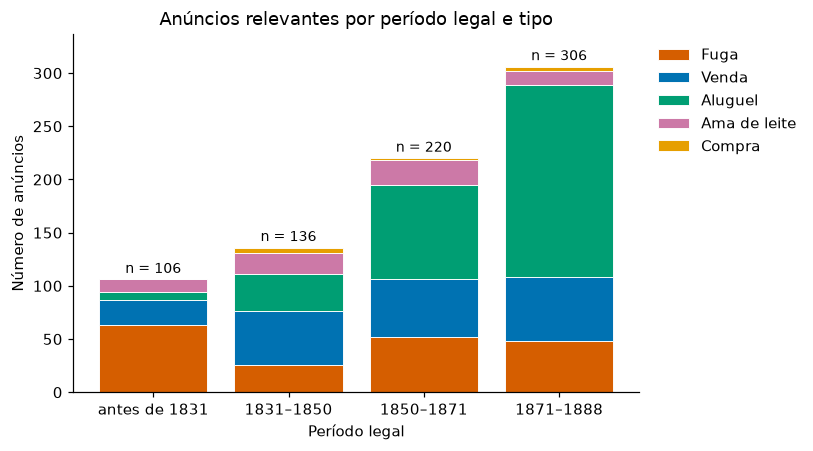

In [4]:
graf = pd.crosstab(df["periodo"], df["tipo"])
graf.columns = [ROTULO_TIPO[c] for c in graf.columns]
cores1 = {ROTULO_TIPO[k]: COR[k] for k in TIPOS}
barras_empilhadas(graf, cores1, "Anúncios relevantes por período legal e tipo", "Período legal", "Número de anúncios",
                  n_topo=graf.sum(axis=1).astype(int).tolist())

**O que mostra:** são 768 anúncios relevantes. O período com mais anúncios é 1871–1888 (306), seguido de 1850–1871 (220), 1831–1850 (136) e antes de 1831 (106). O tipo mais comum é aluguel (312), depois fuga (189) e venda (188); ama de leite tem 68 e compra só 11. Compra é pouco numerosa para qualquer comparação.

## 2. Sexo da pessoa anunciada
A coluna `c_sexo` tem `f`, `m`, `ambos` (o anúncio fala de mais de uma pessoa) ou vazio (**não diz**).
Abaixo, a **proporção** em cada grupo.

> **Aviso:** essa proporção vem das **frases de busca**, não da população. Buscamos, por exemplo, "preta com leite"
> (que só pode ser mulher) e "escravo fugido". Os grupos de ama de leite e de aluguel são
> dominados por mulheres *por causa do que procuramos*, não porque a população era assim.

In [5]:
df["sexo"] = df["c_sexo"].fillna("não diz")
SEXOS = ["f", "m", "ambos", "não diz"]
ROT_SEXO = {"f": "Feminino", "m": "Masculino", "ambos": "Ambos", "não diz": "Não diz"}
cores_sexo = {ROT_SEXO[k]: COR[k] for k in SEXOS}

def prop_sexo(coluna):
    t = pd.crosstab(df[coluna], df["sexo"]).reindex(columns=SEXOS, fill_value=0)
    n = t.sum(axis=1)
    p = t.div(n, axis=0)
    p.columns = [ROT_SEXO[c] for c in p.columns]
    return p, n

p_per, n_per = prop_sexo("periodo")
p_tipo, n_tipo = prop_sexo("tipo")
print("Sexo por período (%):"); print((p_per * 100).round(1).assign(n=n_per))
print("\nSexo por tipo (%):"); print((p_tipo * 100).round(1).assign(n=n_tipo))

Sexo por período (%):
               Feminino  Masculino  Ambos  Não diz    n
periodo                                                
antes de 1831      39.6       34.0    3.8     22.6  106
1831–1850          38.2       49.3    9.6      2.9  136
1850–1871          45.5       33.6    8.2     12.7  220
1871–1888          57.2       32.4    2.6      7.8  306

Sexo por tipo (%):
              Feminino  Masculino  Ambos  Não diz    n
tipo                                                  
fuga              14.3       45.0    1.6     39.2  189
venda             42.6       44.1   11.7      1.6  188
aluguel           63.5       32.7    3.8      0.0  312
ama_de_leite      86.8        2.9    5.9      4.4   68
compra            45.5       36.4   18.2      0.0   11


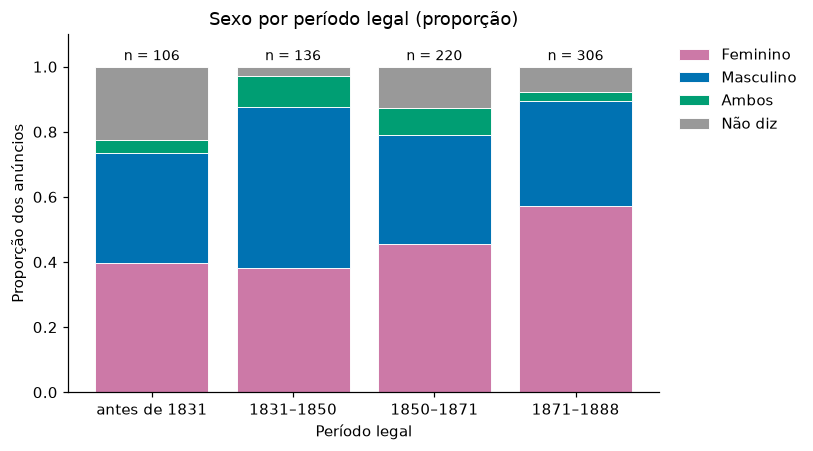

In [6]:
barras_empilhadas(p_per, cores_sexo, "Sexo por período legal (proporção)", "Período legal", "Proporção dos anúncios",
                  proporcao=True, n_topo=n_per.astype(int).tolist())

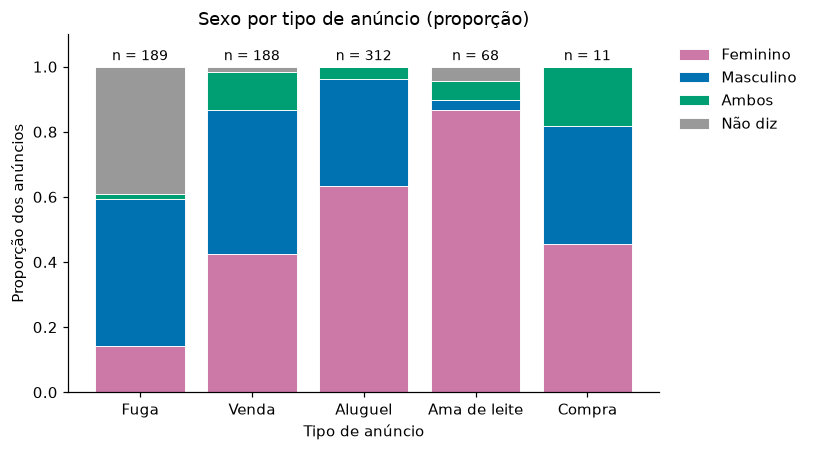

In [7]:
p_tipo.index = [ROTULO_TIPO[i] for i in p_tipo.index]
barras_empilhadas(p_tipo, cores_sexo, "Sexo por tipo de anúncio (proporção)", "Tipo de anúncio", "Proporção dos anúncios",
                  proporcao=True, n_topo=n_tipo.astype(int).tolist())

**O que mostra:** nos anúncios de **ama de leite**, 86,8% são femininos, e em **aluguel** 63,5%; já em **fuga** só 14,3% são femininos, mas 39,2% **não dizem o sexo** (o anúncio descreve a pessoa sem usar uma palavra que o indique). Por período, o feminino sobe de 38,2% (1831–1850) para 57,2% (1871–1888), porém isso acompanha a mudança do **tipo** dominante (aluguel passa de 35 para 181 anúncios) e **não** deve ser lido como mudança na população.

## 3. Idade
Nem todo anúncio diz a idade. Primeiro, quantos dizem. Depois, as faixas: **até 12**, **13–20**, **21–35** e **36 ou mais**.
Quando o anúncio dá um intervalo ("de 20 a 25 anos"), usamos o ponto médio.

In [8]:
df["idade"] = df[["c_idade_min", "c_idade_max"]].astype(float).mean(axis=1)
tem = df["idade"].notna()
resumo = pd.DataFrame({"anúncios": df.groupby("periodo", observed=True).size(),
                       "com idade": df[tem].groupby("periodo", observed=True).size()}).fillna(0).astype(int)
resumo["% com idade"] = (resumo["com idade"] / resumo["anúncios"] * 100).round(1)
resumo.loc["Total"] = [len(df), int(tem.sum()), round(tem.mean() * 100, 1)]
resumo

,anúncios,com idade,% com idade
periodo,,,
antes de 1831,106,12,11.3
1831–1850,136,37,27.2
1850–1871,220,30,13.6
1871–1888,306,23,7.5
Total,768,102,13.3


faixa          até 12  13–20  21–35  36+
periodo                                 
antes de 1831       1      7      3    1
1831–1850           5     25      5    2
1850–1871           5     15      6    4
1871–1888           2     13      6    2


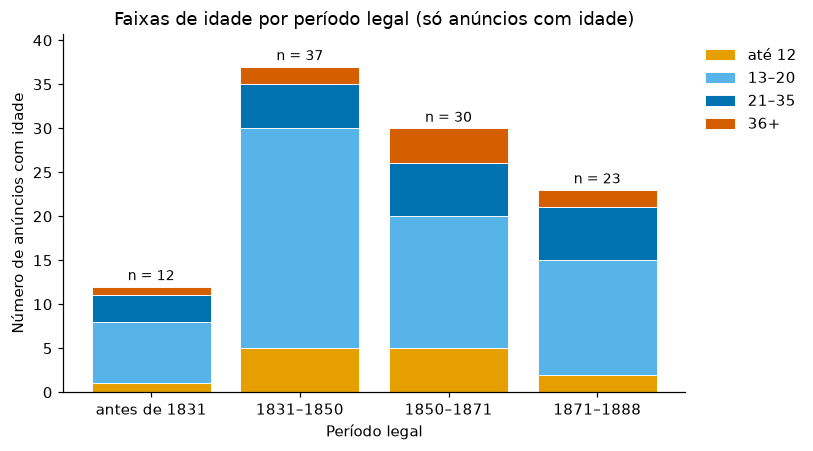

In [9]:
FAIXAS = ["até 12", "13–20", "21–35", "36+"]
df["faixa"] = pd.cut(df["idade"], bins=[-1, 12, 20, 35, 200], labels=FAIXAS)
t3 = pd.crosstab(df["periodo"], df["faixa"]).reindex(columns=FAIXAS, fill_value=0)
print(t3)
cores3 = dict(zip(FAIXAS, ["#E69F00", "#56B4E9", "#0072B2", "#D55E00"]))
barras_empilhadas(t3, cores3, "Faixas de idade por período legal (só anúncios com idade)", "Período legal",
                  "Número de anúncios com idade", n_topo=t3.sum(axis=1).astype(int).tolist())

**O que mostra:** só **102 dos 768** anúncios (13,3%) trazem idade; a taxa varia de 27,2% em 1831–1850 a 7,5% em 1871–1888. Entre os 102, a faixa de **13–20 anos** é a maior em todos os períodos (60 de 102, somando os quatro). Como cada barra tem poucos casos (de 12 a 37), as diferenças entre períodos são frágeis.

## 4. Nações africanas mais citadas
A coluna `c_nacoes` é uma **lista** (um anúncio pode citar mais de uma). "Nação" aqui é o termo usado no anúncio
(Benguela, Mina, Congo…), que dizia de onde vinha ou a que grupo era associada a pessoa; não é uma identidade que ela
mesma escolheu. Contamos quantos anúncios citam cada nação e mostramos as 8 mais citadas em cada período.

Anúncios que citam alguma nação, por período:
{'antes de 1831': 33, '1831–1850': 14, '1850–1871': 7, '1871–1888': 1}

Nações no total: 15


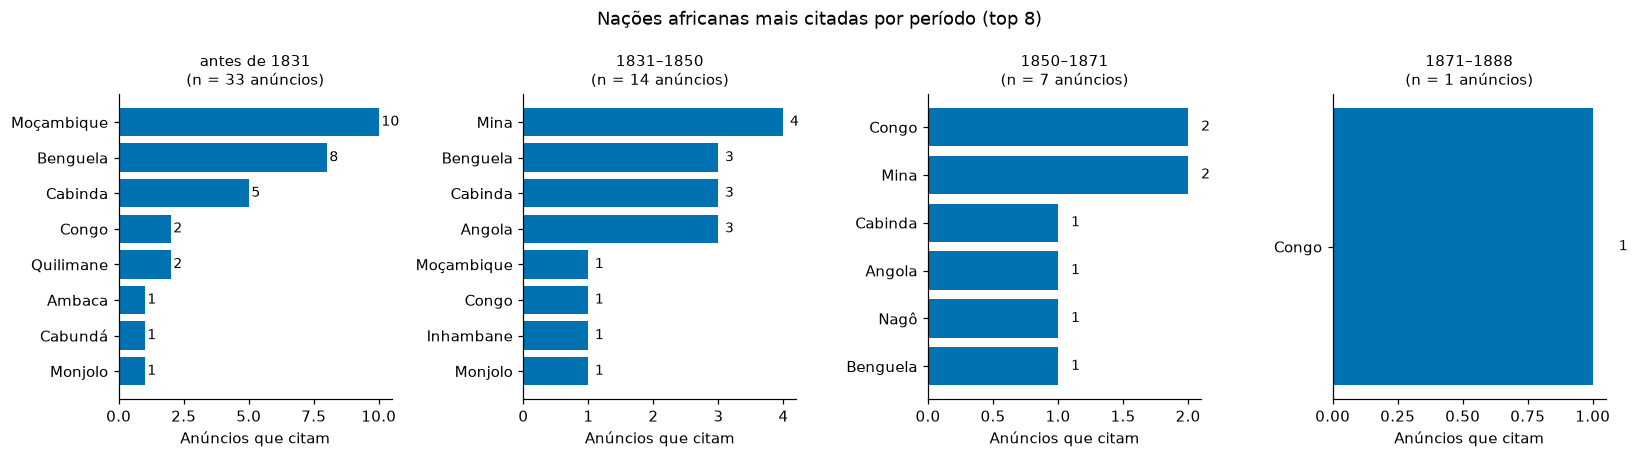

antes de 1831 {'Moçambique': 10, 'Benguela': 8, 'Cabinda': 5, 'Congo': 2, 'Quilimane': 2, 'Ambaca': 1, 'Cabundá': 1, 'Monjolo': 1}
1831–1850 {'Mina': 4, 'Benguela': 3, 'Cabinda': 3, 'Angola': 3, 'Moçambique': 1, 'Congo': 1, 'Inhambane': 1, 'Monjolo': 1}
1850–1871 {'Congo': 2, 'Mina': 2, 'Cabinda': 1, 'Angola': 1, 'Nagô': 1, 'Benguela': 1}
1871–1888 {'Congo': 1}


In [10]:
nac = df[["periodo", "c_nacoes"]].explode("c_nacoes").dropna(subset=["c_nacoes"])
com_nacao = df[df["c_nacoes"].map(len) > 0].groupby("periodo", observed=True).size()
print("Anúncios que citam alguma nação, por período:"); print(com_nacao.reindex(PERIODOS, fill_value=0).to_dict())
top = nac["c_nacoes"].value_counts()
print("\nNações no total:", len(top))
fig, eixos = plt.subplots(1, 4, figsize=(15, 4.2))
for ax, per in zip(eixos, PERIODOS):
    c = nac[nac["periodo"] == per]["c_nacoes"].value_counts().head(8)
    if len(c) == 0:
        ax.text(0.5, 0.5, "nenhuma nação\ncitada", ha="center", va="center", transform=ax.transAxes); ax.set_axis_off()
    else:
        ax.barh(c.index[::-1], c.values[::-1], color="#0072B2")
        for y, v in enumerate(c.values[::-1]):
            ax.text(v + 0.1, y, str(v), va="center", fontsize=9)
    ax.set_title(f"{per}\n(n = {int(com_nacao.get(per, 0))} anúncios)", fontsize=10)
    ax.set_xlabel("Anúncios que citam")
fig.suptitle("Nações africanas mais citadas por período (top 8)")
fig.tight_layout(); plt.show()
for per in PERIODOS:
    print(per, nac[nac["periodo"] == per]["c_nacoes"].value_counts().head(8).to_dict())

**O que mostra:** a citação de nação **cai muito ao longo do tempo**: 33 anúncios antes de 1831, 14 em 1831–1850, 7 em 1850–1871 e apenas 1 em 1871–1888 (no total aparecem 15 nações). Antes de 1831 lideram Moçambique (10), Benguela (8) e Cabinda (5); em 1831–1850, Mina (4). Com tão poucos casos, a ordem das nações no ranking pode mudar com poucos anúncios a mais.

## 5. Condição da pessoa
`c_condicao` diz se o anúncio trata a pessoa como **escravizada**, **forra**, **livre** ou se **não dá para saber** (desconhecida).
Em branco, o programa não achou nenhuma palavra de condição ("sem informação").

Contagens:
condicao      escravizado  forro  livre  desconhecida  sem informação  total
tipo                                                                        
fuga                   63     11      3             0             112    189
venda                  26      1      0           161               0    188
aluguel                34      7      5           266               0    312
ama_de_leite            5      3      0            60               0     68
compra                  5      0      0             6               0     11

Proporção (%):
condicao      escravizado  forro  livre  desconhecida  sem informação
tipo                                                                 
fuga                 33.3    5.8    1.6           0.0            59.3
venda                13.8    0.5    0.0          85.6             0.0
aluguel              10.9    2.2    1.6          85.3             0.0
ama_de_leite          7.4    4.4    0.0          88.2             0.0
compra        

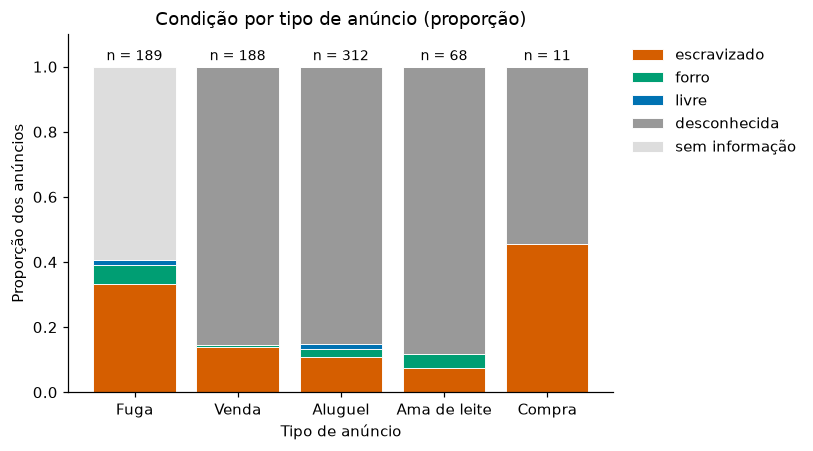

In [11]:
df["condicao"] = df["c_condicao"].fillna("sem informação")
CONDS = ["escravizado", "forro", "livre", "desconhecida", "sem informação"]
t5 = pd.crosstab(df["tipo"], df["condicao"]).reindex(columns=CONDS, fill_value=0)
n5 = t5.sum(axis=1)
p5 = t5.div(n5, axis=0)
print("Contagens:"); print(t5.assign(total=n5))
print("\nProporção (%):"); print((p5 * 100).round(1))
p5.index = [ROTULO_TIPO[i] for i in p5.index]
barras_empilhadas(p5, {k: COR[k] for k in CONDS}, "Condição por tipo de anúncio (proporção)", "Tipo de anúncio",
                  "Proporção dos anúncios", proporcao=True, n_topo=n5.astype(int).tolist())

**O que mostra:** em **aluguel**, 85,3% (266 de 312) estão como "desconhecida" e só 10,9% como escravizado; em **venda** e **ama de leite** o padrão é parecido (85,6% e 88,2%). Isso quer dizer que **o texto não afirma a condição** (o anúncio fala em "uma preta", por exemplo), e não que as pessoas fossem livres. Em **fuga**, 59,3% (112 de 189) ficam "sem informação" e 33,3% saem como escravizados.

## 6. Recompensa nas fugas
Anúncios de fuga costumam oferecer **gratificação** a quem capturasse a pessoa. `c_recompensa` marca se o anúncio a menciona
e `c_valor` guarda o valor, **como aparece no texto** (e lido por OCR, então pode ter erro).

In [12]:
fu = df[df["c_tipo"] == "fuga"]
t6 = fu.groupby("periodo", observed=True).agg(fugas=("id", "size"), com_recompensa=("c_recompensa", "sum"))
t6["com_recompensa"] = t6["com_recompensa"].astype(int)
t6["% com recompensa"] = (t6["com_recompensa"] / t6["fugas"] * 100).round(1)
t6.loc["Total"] = [len(fu), int(fu["c_recompensa"].sum()), round(fu["c_recompensa"].mean() * 100, 1)]
print(t6)
print("\nRecompensa em anúncios que NÃO são fuga:", int(df[df["c_tipo"] != "fuga"]["c_recompensa"].sum()))
print("Fugas com valor lido:", int(fu["c_valor"].notna().sum()))
fu[fu["c_valor"].notna()][["id", "ano", "c_valor"]]

               fugas  com_recompensa  % com recompensa
periodo                                               
antes de 1831     63              33              52.4
1831–1850         26              16              61.5
1850–1871         52              10              19.2
1871–1888         48               5              10.4
Total            189              64              33.9

Recompensa em anúncios que NÃO são fuga: 1
Fugas com valor lido: 3


,id,ano,c_valor
3,5891,1821,1S
9,5898,1821,32:000
211,6988,1850,6s


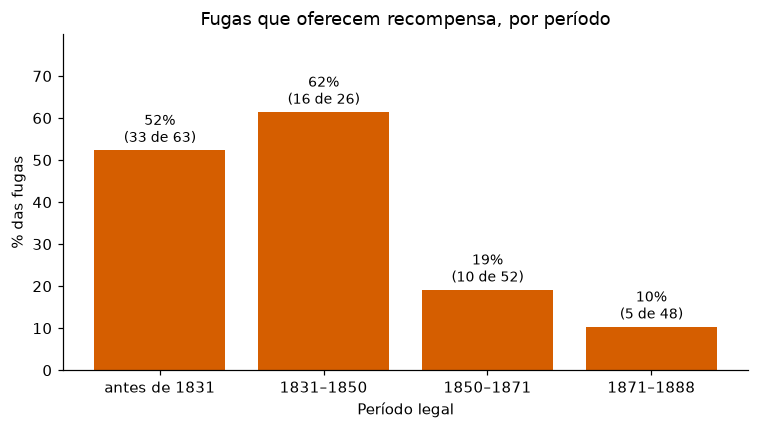

In [13]:
g = t6.drop("Total")
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(len(g)), g["% com recompensa"], color="#D55E00")
for i, (pct, n, k) in enumerate(zip(g["% com recompensa"], g["fugas"], g["com_recompensa"])):
    ax.text(i, pct + 0.8, f"{pct:.0f}%\n({k} de {n})", ha="center", va="bottom", fontsize=9)
ax.set_xticks(range(len(g))); ax.set_xticklabels(g.index)
ax.set_ylim(0, max(g["% com recompensa"].max() * 1.3, 10))
ax.set_title("Fugas que oferecem recompensa, por período"); ax.set_xlabel("Período legal"); ax.set_ylabel("% das fugas")
fig.tight_layout(); plt.show()

**O que mostra:** 64 das 189 fugas (33,9%) oferecem recompensa, e a proporção **cai com o tempo**: 52,4% antes de 1831, 61,5% em 1831–1850, 19,2% em 1850–1871 e 10,4% em 1871–1888. O valor aparece em apenas 3 fugas (1S, 32:000 e 6s), então **não dá para analisar valores**: são poucos, em moedas e formatos diferentes, e lidos por OCR.

## 7. Densidade: anúncios relevantes por página
Cada acervo (jornal e década) tem páginas de qualidade e tamanho diferentes, e nós só lemos páginas que a busca apontou.
Dividimos o número de anúncios relevantes pelo número de páginas lidas (`status = ok`) para ver o efeito de cada acervo.

In [14]:
pg = ler_tudo(lambda: db.table("paginas").select("id,bib,ano").eq("status", "ok").order("id"))
paginas_bib = pg.groupby("bib").size().rename("páginas lidas")
rel_bib = df.groupby("bib").size().rename("anúncios relevantes")
nome_bib = df.drop_duplicates("bib").set_index("bib")["acervo"].rename("acervo")
t7 = pd.concat([paginas_bib, rel_bib], axis=1).join(nome_bib).fillna({"anúncios relevantes": 0})
t7["anúncios relevantes"] = t7["anúncios relevantes"].astype(int)
t7["por página"] = (t7["anúncios relevantes"] / t7["páginas lidas"]).round(2)
t7 = t7.sort_values("acervo")
t7.loc["Total"] = [t7["páginas lidas"].sum(), t7["anúncios relevantes"].sum(), "",
                   round(t7["anúncios relevantes"].sum() / t7["páginas lidas"].sum(), 2)]
t7

,páginas lidas,anúncios relevantes,acervo,por página
bib,,,,
094170_01,35,110,Diário do Rio de Janeiro (RJ) - 1821 a 1858,3.14
706744,5,5,Imperio do Brasil: Diario Fluminense (RJ) - 18...,1.00
364568_03,9,127,Jornal do Commercio (RJ) - 1840 a 1849,14.11
364568_04,8,134,Jornal do Commercio (RJ) - 1850 a 1859,16.75
364568_05,24,27,Jornal do Commercio (RJ) - 1860 a 1869,1.12
364568_06,30,322,Jornal do Commercio (RJ) - 1870 a 1879,10.73
364568_07,14,43,Jornal do Commercio (RJ) - 1880 a 1889,3.07
364568_01,15,0,NaN,0.00
364568_02,18,0,NaN,0.00


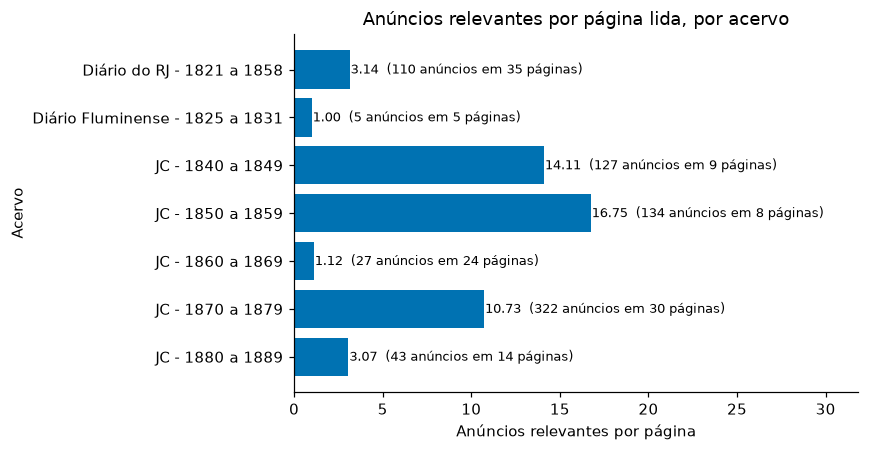

In [15]:
g = t7.drop("Total").dropna(subset=["acervo"])
g = g[g["páginas lidas"] > 0]
rot = g["acervo"].str.replace(" (RJ)", "", regex=False).str.replace("Jornal do Commercio", "JC").str.replace("Diário do Rio de Janeiro", "Diário do RJ").str.replace("Imperio do Brasil: Diario Fluminense", "Diário Fluminense")
fig, ax = plt.subplots(figsize=(8, 4.2))
y = range(len(g))
ax.barh(list(y), g["por página"].astype(float), color="#0072B2")
for i, (v, n, p) in enumerate(zip(g["por página"].astype(float), g["anúncios relevantes"], g["páginas lidas"])):
    ax.text(v + 0.05, i, f"{v:.2f}  ({n} anúncios em {p} páginas)", va="center", fontsize=8.5)
ax.set_yticks(list(y)); ax.set_yticklabels(rot); ax.invert_yaxis()
ax.set_xlim(0, g["por página"].astype(float).max() * 1.9)
ax.set_title("Anúncios relevantes por página lida, por acervo"); ax.set_xlabel("Anúncios relevantes por página"); ax.set_ylabel("Acervo")
fig.tight_layout(); plt.show()

**O que mostra:** a densidade varia muito entre acervos: o Jornal do Commercio de 1850–1859 tem 16,75 anúncios relevantes por página lida e o de 1840–1849 tem 14,11, enquanto o de 1860–1869 tem 1,12 e o Diário do RJ 3,14 (média geral: 4,86). Os acervos com densidade alta foram lidos com páginas escolhidas pela busca, então a diferença mistura **o jornal** e **como escolhemos as páginas**. Contar anúncios por década sem esse cuidado engana.

## 8. O que não podemos concluir

In [16]:
# Números de apoio para a lista abaixo
d80 = df[df["periodo"] == "1871–1888"]
print("1871–1888: anos presentes e anúncios por ano:", d80["ano"].value_counts().sort_index().to_dict())
print("Antes de 1831 por acervo:", df[df["periodo"] == "antes de 1831"]["acervo"].value_counts().to_dict())
alu = d80[d80["c_tipo"] == "aluguel"]
print("Aluguéis 1871–1888:", len(alu), "| condição:", alu["condicao"].value_counts().to_dict())
print("Anúncios por década de acervo (1870 a 1879 vs 1880 a 1889):", df["acervo"].value_counts().to_dict())

1871–1888: anos presentes e anúncios por ano: {1871: 23, 1872: 1, 1873: 19, 1874: 39, 1875: 41, 1877: 45, 1878: 29, 1879: 66, 1880: 34, 1881: 8, 1885: 1}
Antes de 1831 por acervo: {'Diário do Rio de Janeiro (RJ) - 1821 a 1858': 101, 'Imperio do Brasil: Diario Fluminense (RJ) - 1825 a 1831': 5}
Aluguéis 1871–1888: 181 | condição: {'desconhecida': 158, 'escravizado': 21, 'livre': 2}
Anúncios por década de acervo (1870 a 1879 vs 1880 a 1889): {'Jornal do Commercio (RJ) - 1870 a 1879': 322, 'Jornal do Commercio (RJ) - 1850 a 1859': 134, 'Jornal do Commercio (RJ) - 1840 a 1849': 127, 'Diário do Rio de Janeiro (RJ) - 1821 a 1858': 110, 'Jornal do Commercio (RJ) - 1880 a 1889': 43, 'Jornal do Commercio (RJ) - 1860 a 1869': 27, 'Imperio do Brasil: Diario Fluminense (RJ) - 1825 a 1831': 5}


Pontos de atenção, com os números que a saída acima mostra:

- **A amostra vem de frases de busca, não de sorteio.** Proporções de sexo, tipo ou condição descrevem o que a busca encontrou, não a sociedade da época.
- **1881–1888 está pouco coberto.** Dos 306 anúncios de 1871–1888, só 43 vêm do Jornal do Commercio dos anos 1880: 34 de 1880, 8 de 1881 e 1 de 1885. Não há nenhum de 1886 a 1888, então **não dá para falar da Lei dos Sexagenários nem da Lei Áurea**. Em 1871–1888 há ainda anos quase vazios (1872 tem 1 e 1876 não tem nenhum).
- **Antes de 1831 vem quase só do Diário do Rio de Janeiro** (101 de 106 anúncios; os outros 5 são do Diário Fluminense), e o que se vê ali é de um único jornal.
- **Aluguel de 1871–1888 é incerto.** Pela estimativa do grupo, cerca de 4 em cada 10 desses aluguéis ainda não são claramente de pessoas escravizadas (podem ser aluguel de livres, como criados). Na tabela, 158 dos 181 aluguéis desse período estão como "desconhecida".
- **OCR ruim nos anos 1870** (o acervo com mais anúncios, 322): palavras erradas fazem o programa deixar de ver sexo, idade, nação ou condição. Os números de preenchimento (por exemplo, 7,5% com idade em 1871–1888) são, na verdade, um **mínimo**.
- **Poucos casos em vários recortes** (compra tem 11 anúncios; idade tem 102; nação tem 55 no total). Diferenças pequenas entre barras não são evidência.